<a href="https://colab.research.google.com/github/naylaakas/PembelajaranMesin-2026/blob/main/JS06/datasetPBL/Praktikum4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install annoy faiss-cpu hnswlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 7.9 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.5/19.5 MB 40.8 MB/s  0:00:00
  Created wheel for annoy: filename=annoy-1.17.3-cp313-cp313-linux_x86_64.whl size=520036 sha256=88029363fd2145ada725e17f00c6f889aa3b33349ff63fa3c07f3cae1ba32e77
  Stored in directory: /root/.cache/pip/wheels/fc/4e/87/f1f957e7382aa370452cff98276f51686924d5415e449800ed
  Created wheel for hnswlib: filename=hnswlib-0.8.0-cp313-cp313-linux_x86_64.whl size=2679800 sha256=6ac566d30334cc383945d65044a9c3d1c48a79ee3d79ead82f978ec2552c47c8
  Stored in directory: /root/.cache/pip/wheels/35/04/88/b31765a4b9957705e18065db4657e61fc8da54f50

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from annoy import AnnoyIndex
import faiss
import hnswlib

# Load dan gabungkan dataset milikmu
df_cafes = pd.read_csv('cafes.csv')
df_reviews = pd.read_csv('reviews.csv')
df = pd.merge(df_reviews, df_cafes, on='cafe_id', how='left', suffixes=('_review', '_cafe'))

# Siapkan dataset 5D (5 fitur numerik) bertipe float32
fitur_5d = ['rating_review', 'rating_cafe', 'review_count', 'latitude', 'longitude']
X_5d = StandardScaler().fit_transform(df[fitur_5d].fillna(0).values).astype(np.float32)

n_data, dim = X_5d.shape
query = X_5d[1000:1001].copy()  # ambil 1 sampel query dari dataset
k = 10                          # cari 10 tetangga terdekat

print(f"Dataset siap: n_data = {n_data}, dim = {dim}, dtype = {X_5d.dtype}")

Dataset siap: n_data = 2230, dim = 5, dtype = float32


In [3]:
# ===============================
# 1. Annoy (Euclidean)
# ===============================
print("=== Annoy (Euclidean) ===")
ann_index = AnnoyIndex(dim, 'euclidean')

start = time.time()
for i in range(n_data):
    ann_index.add_item(i, X_5d[i])
ann_index.build(10)  # 10 trees
build_time_ann = (time.time() - start) * 1000  # ms

start = time.time()
neighbors_ann = ann_index.get_nns_by_vector(query[0], k, include_distances=True)
query_time_ann = (time.time() - start) * 1000  # ms

print(f"Build time : {build_time_ann:.4f} ms")
print(f"Query time : {query_time_ann:.4f} ms")
print("Neighbors  :", neighbors_ann[0][:5], "...")

# ===============================
# 2. FAISS (IndexFlatL2)
# ===============================
print("\n=== FAISS (IndexFlatL2) ===")
faiss_index = faiss.IndexFlatL2(dim)

start = time.time()
faiss_index.add(X_5d)
build_time_faiss = (time.time() - start) * 1000  # ms

start = time.time()
distances_faiss, indices_faiss = faiss_index.search(query, k)
query_time_faiss = (time.time() - start) * 1000  # ms

print(f"Build time : {build_time_faiss:.4f} ms")
print(f"Query time : {query_time_faiss:.4f} ms")
print("Neighbors  :", indices_faiss[0][:5], "...")

# ===============================
# 3. HNSW (hnswlib - L2)
# ===============================
print("\n=== HNSW (hnswlib - L2) ===")
hnsw_index = hnswlib.Index(space='l2', dim=dim)

start = time.time()
hnsw_index.init_index(max_elements=n_data, ef_construction=200, M=16)
hnsw_index.add_items(X_5d)
build_time_hnsw = (time.time() - start) * 1000  # ms

hnsw_index.set_ef(50)

start = time.time()
labels_hnsw, distances_hnsw = hnsw_index.knn_query(query, k=k)
query_time_hnsw = (time.time() - start) * 1000  # ms

print(f"Build time : {build_time_hnsw:.4f} ms")
print(f"Query time : {query_time_hnsw:.4f} ms")
print("Neighbors  :", labels_hnsw[0][:5], "...")

=== Annoy (Euclidean) ===
Build time : 96.1709 ms
Query time : 0.2167 ms
Neighbors  : [992, 993, 994, 995, 996] ...

=== FAISS (IndexFlatL2) ===
Build time : 0.2627 ms
Query time : 0.2987 ms
Neighbors  : [992 993 994 995 996] ...

=== HNSW (hnswlib - L2) ===
Build time : 423.4118 ms
Query time : 0.2141 ms
Neighbors  : [992 993 996 997 998] ...


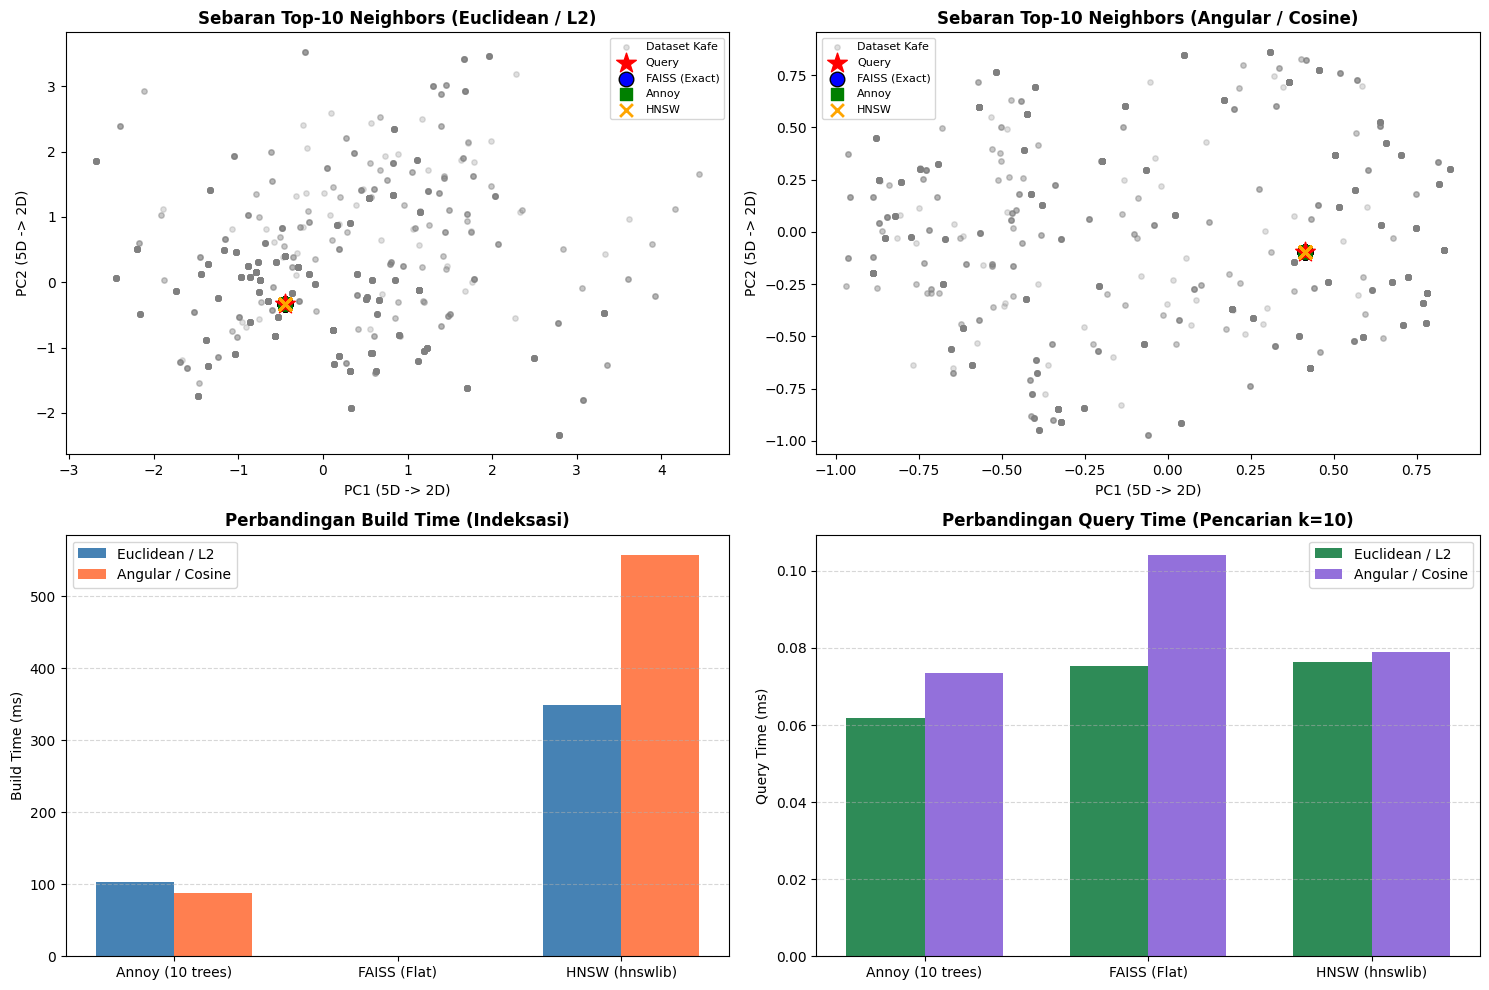


=== TABEL PERBANDINGAN ANNOY VS FAISS VS HNSW (DATASET KAFE 5D) ===
 Distance Metric  Model / Library Dimensi & Data             Top-5 Neighbors  Build Time (ms)  Query Time (ms)
  Euclidean / L2 Annoy (10 trees)      5D (2230)   [992, 993, 994, 995, 996]         103.6670           0.0618
  Euclidean / L2     FAISS (Flat)      5D (2230)   [992, 993, 994, 995, 996]           0.0873           0.0753
  Euclidean / L2   HNSW (hnswlib)      5D (2230)   [992, 993, 997, 998, 999]         348.6497           0.0763
Angular / Cosine Annoy (10 trees)      5D (2230)   [992, 993, 994, 995, 996]          87.5504           0.0734
Angular / Cosine     FAISS (Flat)      5D (2230) [1001, 1000, 999, 998, 997]           0.0811           0.1042
Angular / Cosine   HNSW (hnswlib)      5D (2230) [992, 994, 995, 1000, 1001]         557.7779           0.0789


In [4]:
hasil_perbandingan = []
visual_data = {}

for metric_label in ['Euclidean / L2', 'Angular / Cosine']:
    X_work = X_5d.copy()
    q_work = query.copy()

    if metric_label == 'Euclidean / L2':
        ann_metric = 'euclidean'
        hnsw_space = 'l2'
        faiss_idx = faiss.IndexFlatL2(dim)
    else:
        ann_metric = 'angular'
        hnsw_space = 'cosine'
        faiss.normalize_L2(X_work)
        faiss.normalize_L2(q_work)
        faiss_idx = faiss.IndexFlatIP(dim)

    # --- 1. ANNOY ---
    ann = AnnoyIndex(dim, ann_metric)
    t0 = time.time()
    for i in range(n_data):
        ann.add_item(i, X_work[i])
    ann.build(10)
    t_build_ann = (time.time() - t0) * 1000

    t0 = time.time()
    idx_ann = ann.get_nns_by_vector(q_work[0], k)
    t_query_ann = (time.time() - t0) * 1000

    # --- 2. FAISS ---
    t0 = time.time()
    faiss_idx.add(X_work)
    t_build_faiss = (time.time() - t0) * 1000

    t0 = time.time()
    _, idx_faiss = faiss_idx.search(q_work, k)
    t_query_faiss = (time.time() - t0) * 1000
    idx_faiss = idx_faiss[0].tolist()

    # --- 3. HNSW ---
    hnsw = hnswlib.Index(space=hnsw_space, dim=dim)
    t0 = time.time()
    hnsw.init_index(max_elements=n_data, ef_construction=200, M=16)
    hnsw.add_items(X_work)
    t_build_hnsw = (time.time() - t0) * 1000
    hnsw.set_ef(50)

    t0 = time.time()
    idx_hnsw, _ = hnsw.knn_query(q_work, k=k)
    t_query_hnsw = (time.time() - t0) * 1000
    idx_hnsw = idx_hnsw[0].tolist()

    visual_data[metric_label] = (X_work, q_work, idx_ann, idx_faiss, idx_hnsw)

    for metode, b_time, q_time, nbrs in [
        ('Annoy (10 trees)', t_build_ann,   t_query_ann,   idx_ann[:5]),
        ('FAISS (Flat)',     t_build_faiss, t_query_faiss, idx_faiss[:5]),
        ('HNSW (hnswlib)',   t_build_hnsw,  t_query_hnsw,  idx_hnsw[:5]),
    ]:
        hasil_perbandingan.append({
            'Distance Metric': metric_label,
            'Model / Library': metode,
            'Dimensi & Data': f"5D ({n_data})",
            'Top-5 Neighbors': str(nbrs),
            'Build Time (ms)': round(b_time, 4),
            'Query Time (ms)': round(q_time, 4)
        })

df_hasil_p4 = pd.DataFrame(hasil_perbandingan)

# ===============================
# VISUALISASI PLOT
# ===============================
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Plot 1 & 2 (Baris Atas): Proyeksi PCA 2D Sebaran Tetangga Terdekat per Metric
for col_idx, metric_label in enumerate(['Euclidean / L2', 'Angular / Cosine']):
    ax = axes[0, col_idx]
    X_w, q_w, i_ann, i_faiss, i_hnsw = visual_data[metric_label]
    pca = PCA(n_components=2, random_state=42)
    X_2d_proj = pca.fit_transform(X_w)
    q_2d_proj = pca.transform(q_w)

    ax.scatter(X_2d_proj[:, 0], X_2d_proj[:, 1], alpha=0.25, s=15, color='gray', label='Dataset Kafe')
    ax.scatter(q_2d_proj[:, 0], q_2d_proj[:, 1], c='red', marker='*', s=220, zorder=6, label='Query')
    ax.scatter(X_2d_proj[i_faiss, 0], X_2d_proj[i_faiss, 1], c='blue', s=110, edgecolor='k', zorder=4, label='FAISS (Exact)')
    ax.scatter(X_2d_proj[i_ann, 0], X_2d_proj[i_ann, 1], c='green', marker='s', s=65, zorder=5, label='Annoy')
    ax.scatter(X_2d_proj[i_hnsw, 0], X_2d_proj[i_hnsw, 1], c='orange', marker='x', s=85, linewidths=2, zorder=7, label='HNSW')
    ax.set_title(f"Sebaran Top-10 Neighbors ({metric_label})", fontweight='bold')
    ax.set_xlabel("PC1 (5D -> 2D)")
    ax.set_ylabel("PC2 (5D -> 2D)")
    ax.legend(fontsize=8)

# Plot 3 (Kiri Bawah): Perbandingan Build Time (ms)
ax_b = axes[1, 0]
models = ['Annoy (10 trees)', 'FAISS (Flat)', 'HNSW (hnswlib)']
x = np.arange(len(models))
w = 0.35
b_euc = df_hasil_p4[df_hasil_p4['Distance Metric'] == 'Euclidean / L2']['Build Time (ms)'].values
b_ang = df_hasil_p4[df_hasil_p4['Distance Metric'] == 'Angular / Cosine']['Build Time (ms)'].values

ax_b.bar(x - w/2, b_euc, w, label='Euclidean / L2', color='steelblue')
ax_b.bar(x + w/2, b_ang, w, label='Angular / Cosine', color='coral')
ax_b.set_xticks(x)
ax_b.set_xticklabels(models)
ax_b.set_ylabel('Build Time (ms)')
ax_b.set_title('Perbandingan Build Time (Indeksasi)', fontweight='bold')
ax_b.legend()
ax_b.grid(axis='y', linestyle='--', alpha=0.5)

# Plot 4 (Kanan Bawah): Perbandingan Query Time (ms)
ax_q = axes[1, 1]
q_euc = df_hasil_p4[df_hasil_p4['Distance Metric'] == 'Euclidean / L2']['Query Time (ms)'].values
q_ang = df_hasil_p4[df_hasil_p4['Distance Metric'] == 'Angular / Cosine']['Query Time (ms)'].values

ax_q.bar(x - w/2, q_euc, w, label='Euclidean / L2', color='seagreen')
ax_q.bar(x + w/2, q_ang, w, label='Angular / Cosine', color='mediumpurple')
ax_q.set_xticks(x)
ax_q.set_xticklabels(models)
ax_q.set_ylabel('Query Time (ms)')
ax_q.set_title('Perbandingan Query Time (Pencarian k=10)', fontweight='bold')
ax_q.legend()
ax_q.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Cetak Tabel Hasil
print("\n=== TABEL PERBANDINGAN ANNOY VS FAISS VS HNSW (DATASET KAFE 5D) ===")
print(df_hasil_p4.to_string(index=False))